# Runtime overhead of MCP tool execution

This experiment measures the execution time of authorized MCP operations in three versions of the same Django application: **Baseline**, **Manual-enforcement**, and **System-enforcement**. The comparison examines the cost of adding access control and the additional cost of enforcing application policies through a reusable System.

Two execution modes are evaluated. **Cold-start** includes a new MCP process and session for every invocation, while **Persistent-session** reuses an initialized session. We first examine each experiment independently, then compare the effects of session reuse and workload size.

The timing results are reported for individual tool operations rather than as a single application-wide average. This keeps the differences between lightweight operations and large file reads visible.

## 1. Experimental design

The evaluation uses the same user, seeded resources, and authorized requests across all three implementations. Each scenario is executed 30 times per run, following two warmup calls. Each execution mode uses all six implementation orders, one per run.

| Setting | Value |
|---|---|
| Implementations | Baseline, Manual-enforcement, System-enforcement |
| Modes | Cold-start, Persistent-session |
| Runs | 6 per mode, with varied implementation order |
| Measurements | 30 timed calls per scenario and implementation, per run |
| Warmup | 2 calls before timed measurements |
| Benchmark coverage | 36 reports, 324 scenario-level benchmarks, 9,720 timed calls |
| Excluded from timing | LLM inference, tool preparation, human confirmation, and post-call verification |

Repeated runs allow us to examine variability between measurements taken under different execution orders. The two modes separate full process-level invocations from repeated calls through an existing MCP session.

The version order changes between runs, so the same implementation is not always tested first. The run-level results also let us check whether the differences hold across repetitions, rather than depending on a single set of measurements.

### 1.1. Benchmark scenarios

The nine scenarios cover filesystem operations, database queries, and file reads with increasing input size.

| Group | Scenario | Tool | Workload |
|---|---|---|---|
| Filesystem | LIST | `list_files` | List files under the user's directory |
| Filesystem | SEARCH | `search_files` | Search for `notes` |
| File reads | READ 1 KiB | `read_file` | Small text document |
| File reads | READ 1 MiB | `read_file` | Medium document |
| File reads | READ 10 MiB | `read_file` | Large CSV file |
| Database | SCHEMA | `get_database_schema` | Retrieve database schema |
| Database | SELECT | `execute_sql` | Read file metadata |
| Database | UPDATE | `execute_sql` | Update a user field |
| Filesystem | DELETE | `delete_file` | Delete a file |

Only successful, authorized operations are included. These benchmarks measure execution latency rather than security-test success rates.

### 1.2. Measurements

Each run is summarized from its 30 timed calls. Statistics are then compared across six runs without treating the 180 calls as independent experimental runs.

| Measurement | Meaning | Role in the analysis |
|---|---|---|
| Mean | Average latency | Overall execution time, including slower calls |
| Median (p50) | Middle latency | Primary typical-latency measure |
| p90 | 90th-percentile latency | Slower requests |
| p95 | 95th-percentile latency | Additional tail-latency check |
| p99 | 99th-percentile latency | Supplementary, less stable with 30 calls |
| SD | Standard deviation | Within-run variation |
| IQR | Middle 50% of timings | Variation less affected by extremes |
| Min / max | Smallest and largest observed latency | Observed range |
| Between-run SD | SD of six run medians | Consistency across runs |
| Overhead (ms) | Difference between implementations | Additional execution time |
| Overhead (%) | Relative difference | Proportional cost |
| 95% CI | Uncertainty in mean overhead across runs | Precision of the estimated difference |
| Input / response bytes | Workload and output sizes | Comparability of operations |

For the six-run summary, mean latency is averaged across run means, while median and percentile results summarize the corresponding statistics from the six runs. Overhead is calculated separately for each run, then summarized across runs.

### 1.3. Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import t

VERSIONS = ["v1", "v2", "v3"]
LABELS = {"v1": "Baseline", "v2": "Manual-enforcement", "v3": "System-enforcement"}
COLORS = {"v1": "#64748b", "v2": "#15877f", "v3": "#c47f36"}
SCENARIOS = ["list", "search", "read_small", "read_medium", "read_large", "schema", "select", "update", "delete"]
NAMES = {"list": "LIST", "search": "SEARCH", "read_small": "READ 1 KiB", "read_medium": "READ 1 MiB", "read_large": "READ 10 MiB", "schema": "SCHEMA", "select": "SELECT", "update": "UPDATE", "delete": "DELETE"}
SHORT_OPS = ["list", "search", "read_small", "schema", "select", "update", "delete"]
READS = ["read_small", "read_medium", "read_large"]
PAIRS = [("v2", "v1", "Manual vs Baseline"), ("v3", "v1", "System vs Baseline"), ("v3", "v2", "System vs Manual")]
PAIR_COLORS = [COLORS["v2"], COLORS["v3"], "#7764a6"]

In [2]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "results/runtime_overhead").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find results/runtime_overhead")
RESULTS = ROOT / "results/runtime_overhead"
OUTPUT = RESULTS / "analysis"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 115})

### 1.4. Load and verify the benchmark results

The raw JSON reports retain individual call times, implementation metadata, and input and response sizes. Timings are converted from seconds to milliseconds before analysis.

The original call times remain available for distribution plots and percentile calculations. We also retain response sizes, since a tool returning more data may take longer even without additional authorization work.

In [3]:
timings, reports, saved_medians = [], [], []
for mode in ["cold_start", "persistent_session"]:
    for path in sorted((RESULTS / mode).glob("run_*/overhead_v*.json")):
        run, version = int(path.parent.name.split("_")[1]), path.stem.split("_")[-1]
        report = json.loads(path.read_text())
        reports.append({"mode": mode, "run": run, "version": version, "commit": report.get("commit_info", {}).get("id"), "branch": report.get("commit_info", {}).get("branch"), "machine": report.get("machine_info", {}).get("node")})
        for item in report["benchmarks"]:
            info, stats = item["extra_info"], item["stats"]
            scenario = info["scenario"]
            saved_medians.append({"mode": mode, "run": run, "version": version, "scenario": scenario, "reported": stats["median"] * 1000})
            for i, seconds in enumerate(stats["data"], 1):
                timings.append({"mode": mode, "run": run, "version": version, "scenario": scenario, "call": i, "ms": seconds * 1000, "input_bytes": info.get("input_bytes"), "response_bytes": info.get("response_bytes")})

samples = pd.DataFrame(timings)
report_info = pd.DataFrame(reports)
recorded = pd.DataFrame(saved_medians)
print(f"{len(report_info)} reports | {len(samples):,} timed calls")

36 reports | 9,720 timed calls


In [4]:
keys = ["mode", "run", "version", "scenario"]
expected = pd.MultiIndex.from_product([["cold_start", "persistent_session"], range(1, 7), VERSIONS, SCENARIOS], names=keys)
counts = samples.groupby(keys).size()
assert len(report_info) == 36 and not report_info.duplicated(["mode", "run", "version"]).any()
assert counts.index.equals(expected.sort_values()) and counts.eq(30).all()
assert np.isfinite(samples["ms"]).all() and samples["ms"].gt(0).all()
assert report_info.groupby(["mode", "version"])[["commit", "branch", "machine"]].nunique(dropna=False).le(1).all().all()
print("All 36 reports and 324 benchmark groups verified")

All 36 reports and 324 benchmark groups verified


### 1.5. Calculate latency statistics

In [5]:
run_stats = samples.groupby(keys, as_index=False).agg(
    n=("ms", "size"), mean=("ms", "mean"), median=("ms", "median"),
    p90=("ms", lambda x: x.quantile(.90)), p95=("ms", lambda x: x.quantile(.95)), p99=("ms", lambda x: x.quantile(.99)),
    sd=("ms", "std"), iqr=("ms", lambda x: x.quantile(.75) - x.quantile(.25)),
    minimum=("ms", "min"), maximum=("ms", "max"),
    input_bytes=("input_bytes", "first"), response_bytes=("response_bytes", "first"))
check = run_stats.merge(recorded, on=keys, validate="one_to_one")
assert np.allclose(check["median"], check["reported"], atol=1e-6)
print(f"{len(run_stats)} per-run summaries")

324 per-run summaries


In [6]:
summary = run_stats.groupby(["mode", "scenario", "version"], as_index=False).agg(
    runs=("run", "nunique"), n=("n", "sum"), mean=("mean", "mean"), median=("median", "median"),
    p90=("p90", "median"), p95=("p95", "median"), p99=("p99", "median"),
    sd=("sd", "median"), iqr=("iqr", "median"), run_sd=("median", "std"),
    run_min=("median", "min"), run_max=("median", "max"), minimum=("minimum", "min"), maximum=("maximum", "max"),
    input_bytes=("input_bytes", "median"), response_bytes=("response_bytes", "median"))
assert summary["runs"].eq(6).all()
print(f"{len(summary)} six-run summaries")

54 six-run summaries


In [7]:
wide = run_stats.pivot(index=["mode", "run", "scenario"], columns="version", values="median").reset_index()
differences = []
for version, reference, name in PAIRS:
    rows = wide[["mode", "run", "scenario"]].copy()
    rows["comparison"] = name
    rows["delta_ms"] = wide[version] - wide[reference]
    rows["delta_pct"] = 100 * (wide[version] / wide[reference] - 1)
    differences.append(rows)
differences = pd.concat(differences, ignore_index=True)

In [8]:
overhead = differences.groupby(["mode", "scenario", "comparison"], as_index=False).agg(
    mean_ms=("delta_ms", "mean"), median_ms=("delta_ms", "median"),
    mean_pct=("delta_pct", "mean"), median_pct=("delta_pct", "median"),
    sd=("delta_ms", "std"), n=("run", "size"))
overhead["ci_margin"] = t.ppf(.975, overhead["n"] - 1) * overhead["sd"] / np.sqrt(overhead["n"])
overhead["ci_low"] = overhead["mean_ms"] - overhead["ci_margin"]
overhead["ci_high"] = overhead["mean_ms"] + overhead["ci_margin"]

## 2. Cold-start experiment

In the Cold-start benchmark, each timed invocation launches an MCP process, establishes a session, executes the requested tool, and closes the session. Consequently, the measured latency includes initialization and communication, not only authorization checks.

This mode reflects the cost of an invocation when the application does not keep its MCP session open. It is useful as an initial measurement, although differences between implementations include more than the policy decision itself.

### 2.1. Run 1 results

The first run is examined before combining repeated runs. The table reports the complete statistics from the 30 timed calls for each operation and implementation. All latency values are in milliseconds.

In [9]:
data = run_stats.query("mode == 'cold_start' and run == 1").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(2))

,,Calls,Mean,Median,p90,p95,p99,SD,IQR,Min,Max
Operation,Implementation,,,,,,,,,,
DELETE,Baseline,30,770.91,768.66,784.67,785.65,788.31,8.82,12.20,757.90,789.34
LIST,Baseline,30,748.25,747.14,757.48,758.10,758.92,6.74,11.66,737.40,759.23
READ 10 MiB,Baseline,30,1745.52,1711.28,1885.99,1893.80,1900.45,73.78,20.32,1692.74,1900.86
READ 1 MiB,Baseline,30,755.14,754.95,758.77,759.56,760.79,2.95,4.70,749.90,761.16
READ 1 KiB,Baseline,30,742.38,742.06,748.26,754.36,756.39,5.68,5.73,732.66,756.90
SCHEMA,Baseline,30,741.90,742.37,744.86,745.89,748.90,3.07,4.27,736.13,750.01
SEARCH,Baseline,30,742.62,742.58,748.32,752.72,754.39,4.93,5.66,735.69,754.82
SELECT,Baseline,30,743.32,742.29,750.19,751.47,755.85,4.94,4.77,733.33,757.61
UPDATE,Baseline,30,743.92,742.38,751.13,752.72,758.80,5.42,5.94,735.44,760.84


#### Latency by operation

Median and p90 latency are compared for seven filesystem and database operations. The 1 MiB and 10 MiB reads are examined separately because of their larger execution times.
The solid bars represent median execution time, and the lighter section extends to p90. Showing both in one chart lets us compare typical calls without hiding slower executions.

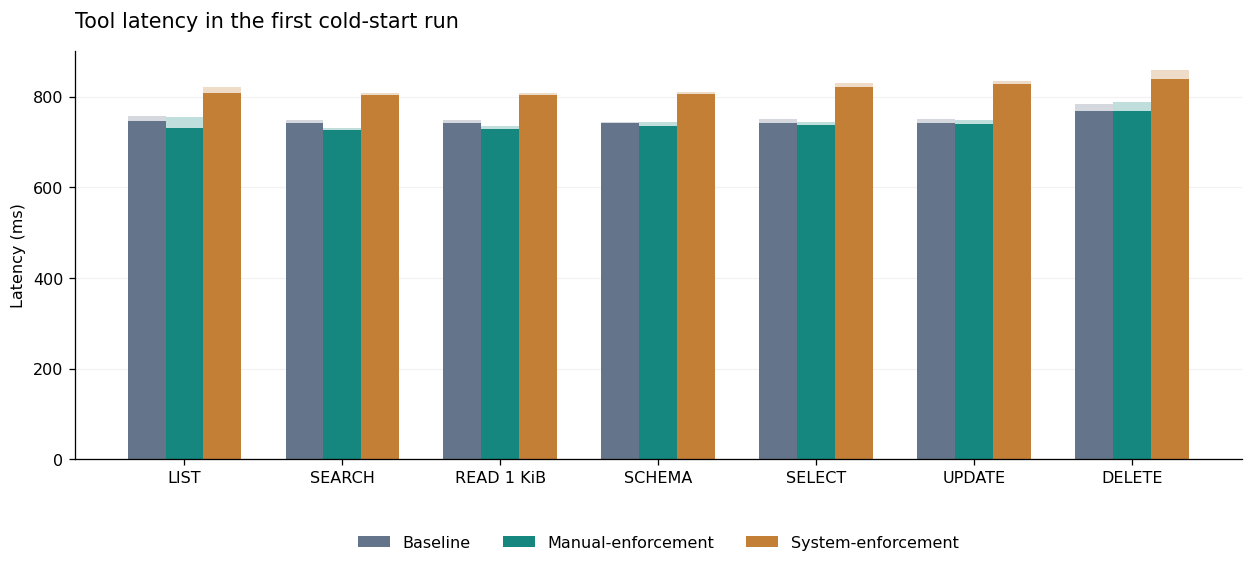

In [10]:
data = run_stats.query("mode == 'cold_start' and run == 1")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency in the first cold-start run", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_first_run_tool_latency.png", dpi=300, bbox_inches="tight")
plt.show()

#### Distribution of file-read latency

The distribution for READ 1 KiB retains the individual measurements rather than reducing them to a single summary. A curve further to the left indicates faster calls; a steeper curve indicates less variation.

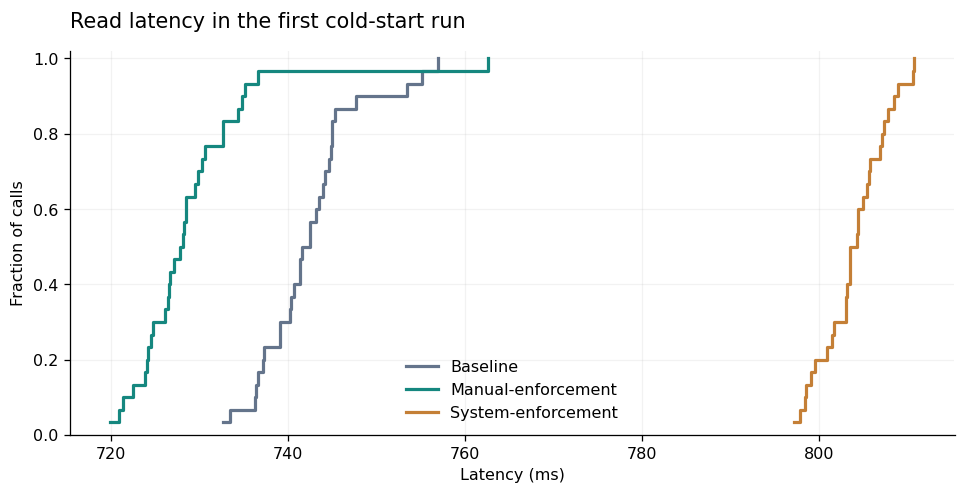

In [11]:
data = samples.query("mode == 'cold_start' and run == 1 and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    values = np.sort(data.loc[data["version"] == version, "ms"])
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=COLORS[version], label=LABELS[version], linewidth=2)
ax.set(xlabel="Latency (ms)", ylabel="Fraction of calls", ylim=(0, 1.02))
ax.set_title("Read latency in the first cold-start run", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_first_run_read_latency_distribution.png", dpi=300)
plt.show()

### 2.2. Results across six runs

The six repetitions are analyzed independently before the overall comparison. Each value in the following table represents the median of 30 calls from one run.

Looking at the runs separately helps determine whether the same version remains slower throughout the experiment or whether the gap changes from one run to another.

In [12]:
data = run_stats.query("mode == 'cold_start'")
by_run = data.pivot(index=["scenario", "version"], columns="run", values="median")
by_run.index = pd.MultiIndex.from_tuples([(NAMES[s], LABELS[v]) for s, v in by_run.index], names=["Operation", "Implementation"])
display(by_run.round(2).rename_axis(columns="Run"))

Run                                   1        2        3        4        5  \
Operation   Implementation                                                    
DELETE      Baseline             768.66   768.58   766.68   771.46   786.19   
            Manual-enforcement   767.89   770.25   767.11   791.40   785.06   
            System-enforcement   838.90   827.70   828.98   828.91   845.43   
LIST        Baseline             747.14   742.27   743.17   743.87   760.47   
            Manual-enforcement   729.95   744.01   748.25   748.40   759.96   
            System-enforcement   807.76   809.27   808.56   808.37   825.78   
READ 10 MiB Baseline            1711.28  1716.93  1715.31  1717.71  1776.22   
            Manual-enforcement  1689.05  1719.25  1739.70  1753.80  1749.83   
            System-enforcement  1769.77  1787.87  1786.87  1789.20  1800.59   
READ 1 MiB  Baseline             754.95   755.88   756.23   754.60   776.55   
            Manual-enforcement   759.46   758.30   767.27   774.28   771.96   
            System-enforcement   814.63   821.27   820.61   819.47   835.93   
READ 1 KiB  Baseline             742.06   740.81   742.27   742.27   753.70   
            Manual-enforcement   727.91   743.37   749.42   761.06   759.76   
            System-enforcement   803.95   807.00   804.91   806.99   824.24   
SCHEMA      Baseline             742.37   743.98   743.31   743.50   760.45   
            Manual-enforcement   734.86   743.59   743.69   759.99   780.99   
            System-enforcement   805.59   808.01   808.50   809.12   825.60   
SEARCH      Baseline             742.58   742.96   741.85   742.28   750.92   
            Manual-enforcement   725.71   742.18   750.02   760.78   750.44   
            System-enforcement   804.31   809.02   807.76   806.52   817.72   
SELECT      Baseline             742.29   744.50   743.15   742.62   761.98   
            Manual-enforcement   737.78   744.93   743.37   767.35   775.79   
            System-enforcement   822.26   811.26   812.30   811.06   827.14   
UPDATE      Baseline             742.38   745.15   748.44   743.87   767.37   
            Manual-enforcement   739.39   746.29   747.62   771.32   760.31   
            System-enforcement   828.40   813.74   814.67   812.51   841.99   

Run                                   6  
Operation   Implementation               
DELETE      Baseline             788.35  
            Manual-enforcement   788.05  
            System-enforcement   842.54  
LIST        Baseline             764.11  
            Manual-enforcement   767.87  
            System-enforcement   845.73  
READ 10 MiB Baseline            1765.52  
            Manual-enforcement  1749.06  
            System-enforcement  1817.72  
READ 1 MiB  Baseline             795.46  
            Manual-enforcement   776.15  
            System-enforcement   835.11  
READ 1 KiB  Baseline             766.86  
            Manual-enforcement   754.10  
            System-enforcement   827.87  
SCHEMA      Baseline             770.76  
            Manual-enforcement   753.41  
            System-enforcement   821.89  
SEARCH      Baseline             750.52  
            Manual-enforcement   768.61  
            System-enforcement   842.29  
SELECT      Baseline             764.25  
            Manual-enforcement   771.09  
            System-enforcement   837.42  
UPDATE      Baseline             792.17  
            Manual-enforcement   764.97  
            System-enforcement   829.12

#### Variation between runs

READ 1 KiB provides a consistent workload for examining changes across the six runs. The lines show the median latency recorded in each run, separately for the three implementations.

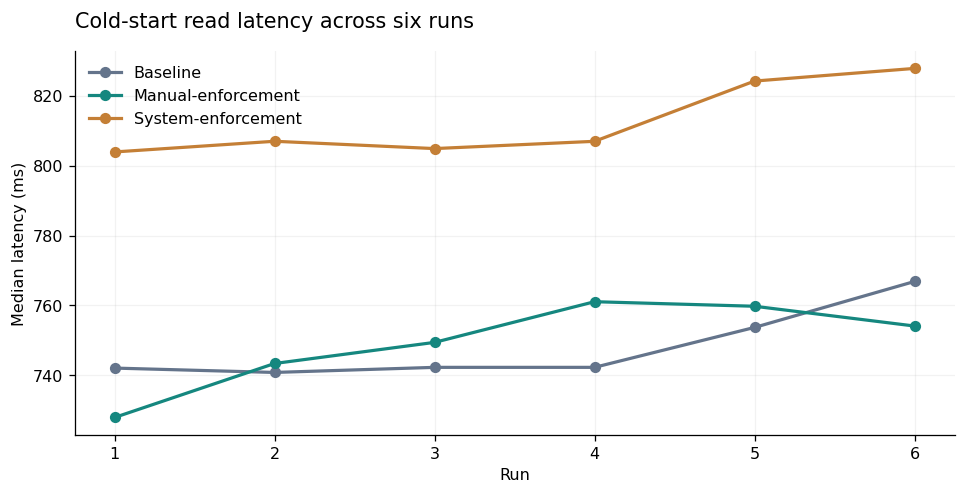

In [13]:
data = run_stats.query("mode == 'cold_start' and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    rows = data[data["version"] == version].sort_values("run")
    ax.plot(rows["run"], rows["median"], marker="o", linewidth=2, color=COLORS[version], label=LABELS[version])
ax.set(xlabel="Run", ylabel="Median latency (ms)", xticks=range(1, 7))
ax.set_title("Cold-start read latency across six runs", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_read_latency_across_six_runs.png", dpi=300)
plt.show()

#### Overall latency statistics

The following table combines the results of six runs for each scenario. Mean latency is averaged across run means. The median, p90, p95, p99, SD and IQR summarize the corresponding run-level statistics. Between-run SD is calculated from the six run medians. Minimum and maximum refer to individual measured calls.

Results remain separated by operation. Averaging the nine workloads into one latency figure would give the large-file read disproportionate influence over the comparison.

In [14]:
data = summary.query("mode == 'cold_start'").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "run_sd": "Between-run SD", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(2))

Calls     Mean   Median      p90      p95  \
Operation   Implementation                                                  
DELETE      Baseline              180   779.93   770.06   789.67   795.36   
            Manual-enforcement    180   782.74   777.65   799.27   803.90   
            System-enforcement    180   839.07   833.94   853.02   859.59   
LIST        Baseline              180   751.09   745.50   756.31   759.54   
            Manual-enforcement    180   763.53   748.33   783.78   795.53   
            System-enforcement    180   821.19   808.91   821.38   829.23   
READ 10 MiB Baseline              180  1768.27  1717.32  1892.33  1897.02   
            Manual-enforcement    180  1773.31  1744.38  1914.41  1922.62   
            System-enforcement    180  1840.10  1788.54  1967.10  1970.34   
READ 1 MiB  Baseline              180   768.11   756.06   759.97   761.72   
            Manual-enforcement    180   771.20   769.62   790.59   804.83   
            System-enforcement    180   825.56   820.94   827.00   830.49   
READ 1 KiB  Baseline              180   749.83   742.27   748.34   753.56   
            Manual-enforcement    180   751.60   751.76   760.85   763.33   
            System-enforcement    180   814.36   807.00   812.64   814.89   
SCHEMA      Baseline              180   751.30   743.74   747.77   749.17   
            Manual-enforcement    180   758.14   748.55   759.45   772.15   
            System-enforcement    180   816.94   808.81   814.70   816.36   
SEARCH      Baseline              180   746.21   742.77   752.98   754.97   
            Manual-enforcement    180   751.55   750.23   763.16   764.18   
            System-enforcement    180   816.89   808.39   814.23   815.45   
SELECT      Baseline              180   751.02   743.83   748.94   750.85   
            Manual-enforcement    180   763.53   756.14   781.13   801.43   
            System-enforcement    180   822.34   817.28   823.75   824.01   
UPDATE      Baseline              180   758.95   746.80   757.30   766.12   
            Manual-enforcement    180   758.18   753.96   760.79   764.48   
            System-enforcement    180   825.91   821.53   827.74   840.10   

                                    p99     SD     IQR  Between-run SD  \
Operation   Implementation                                               
DELETE      Baseline             801.31  12.21   15.55            9.66   
            Manual-enforcement   833.47  16.28   14.30           11.05   
            System-enforcement   861.33  10.72   11.83            7.83   
LIST        Baseline             763.98   7.02    9.42            9.60   
            Manual-enforcement   815.25  21.20   19.70           13.13   
            System-enforcement   832.63   7.67    6.57           15.44   
READ 10 MiB Baseline            1900.36  74.47   20.85           28.98   
            Manual-enforcement  1941.44  80.04   68.05           25.05   
            System-enforcement  1975.32  84.25  172.35           16.00   
READ 1 MiB  Baseline             763.10   3.19    4.42           16.90   
            Manual-enforcement   821.57  18.70   16.52            7.60   
            System-enforcement   840.42   5.82    6.06            8.85   
READ 1 KiB  Baseline             765.37   6.79    7.34           10.40   
            Manual-enforcement   768.26   8.00    8.06           12.36   
            System-enforcement   817.70   4.34    6.26           10.63   
SCHEMA      Baseline             753.42   3.93    5.27           11.99   
            Manual-enforcement   795.69  13.40    7.63           16.35   
            System-enforcement   825.47   5.42    5.00            8.40   
SEARCH      Baseline             765.55   6.96    6.04            4.31   
            Manual-enforcement   766.87   8.65   10.85           14.92   
            System-enforcement   824.06   5.37    5.83           14.32   
SELECT      Baseline             754.69   4.66    4.54           10.37   
            Manual-enf

#### Latency across operations

The six-run summaries compare median and p90 latency for the same seven operations. The heavier file-read workloads are analyzed separately below.


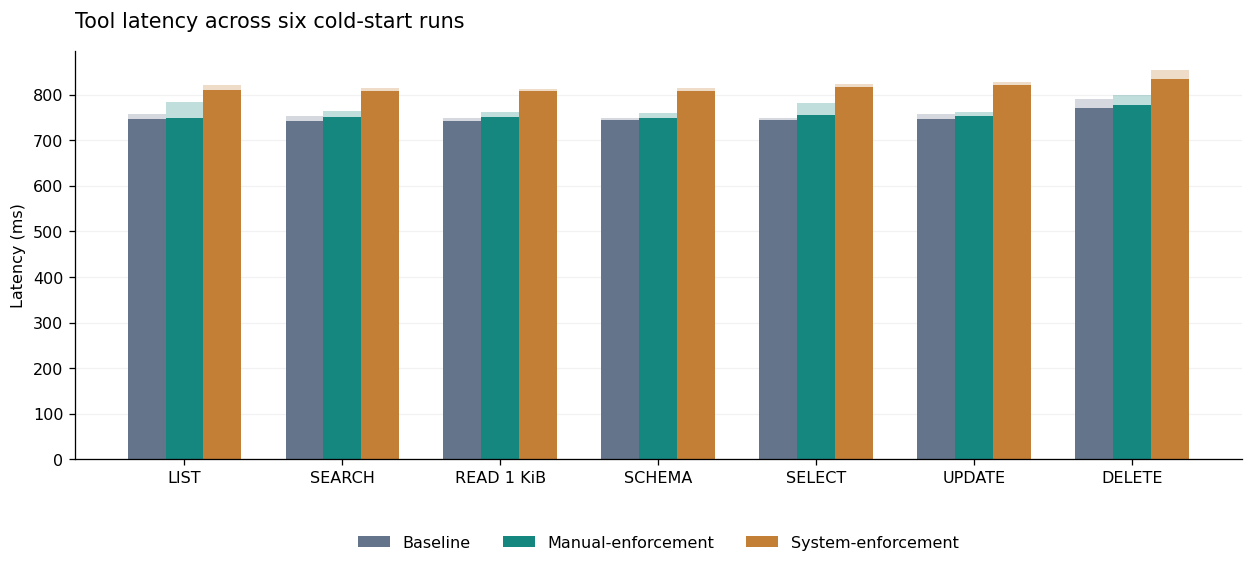

In [15]:
data = summary.query("mode == 'cold_start' ")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency across six cold-start runs", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_tool_latency_six_run_summary.png", dpi=300, bbox_inches="tight")
plt.show()

#### File-read size and latency

The file-read workloads return files of approximately 1 KiB, 1 MiB and 10 MiB. For each file size, all three implementations use the same input size.

Comparing these sizes helps distinguish overhead that is relatively constant per call from additional work that grows as more data is read.

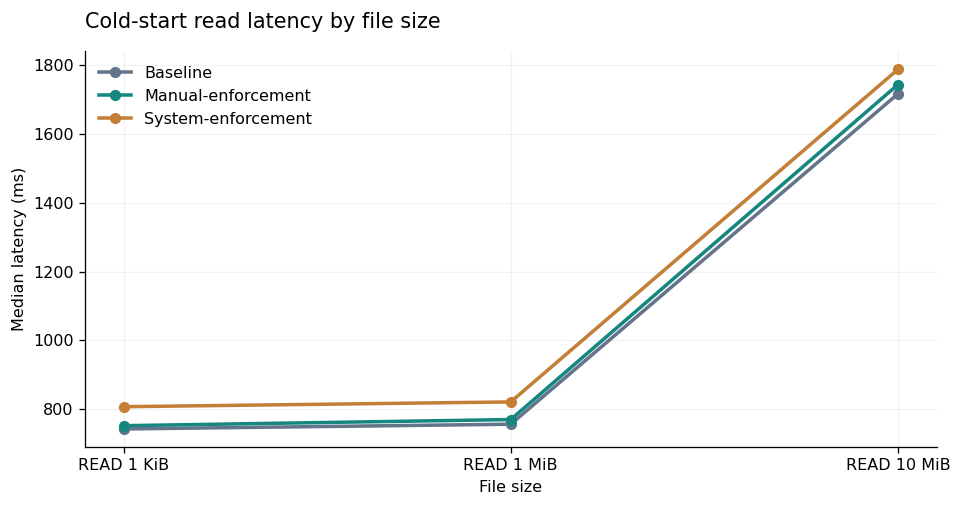

In [16]:
data = summary.query("mode == 'cold_start'")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for version in VERSIONS:
    rows = data[data["version"] == version].set_index("scenario").loc[READS]
    ax.plot(range(3), rows["median"], marker="o", linewidth=2.2, color=COLORS[version], label=LABELS[version])
ax.set_xticks(range(3), [NAMES[s] for s in READS])
ax.set(xlabel="File size", ylabel="Median latency (ms)")
ax.set_title("Cold-start read latency by file size", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_read_latency_by_file_size.png", dpi=300)
plt.show()

### 2.3. Runtime overhead

The same operation is compared between implementations within each run. The differences are then summarized across six runs. Positive values indicate that the first implementation is slower; negative values indicate that it is faster. The table reports both milliseconds and percentages, with a 95% confidence interval for the mean difference.

The three comparisons answer different questions: the cost of manual checks, the cost of the System relative to Baseline, and the difference between the two secured implementations.

In [17]:
data = overhead.query("mode == 'cold_start'").copy()
data["Operation"] = data["scenario"].map(NAMES)
columns = {"mean_ms": "Mean Δ (ms)", "median_ms": "Median Δ (ms)", "mean_pct": "Mean Δ (%)", "median_pct": "Median Δ (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}
display(data.set_index(["Operation", "comparison"])[list(columns)].rename(columns=columns).round(2))

Mean Δ (ms)  Median Δ (ms)  Mean Δ (%)  \
Operation   comparison                                                   
DELETE      Manual vs Baseline         3.31           0.07        0.43   
            System vs Baseline        60.42          59.18        7.80   
            System vs Manual          57.12          58.91        7.35   
LIST        Manual vs Baseline        -0.43           2.75       -0.06   
            System vs Baseline        67.40          65.35        8.98   
            System vs Manual          67.84          65.54        9.05   
READ 10 MiB Manual vs Baseline        -0.38          -7.07       -0.01   
            System vs Baseline        58.18          64.72        3.37   
            System vs Manual          58.56          59.69        3.39   
READ 1 MiB  Manual vs Baseline         2.29           3.46        0.33   
            System vs Baseline        58.89          62.03        7.72   
            System vs Manual          56.60          57.07        7.37   
READ 1 KiB  Manual vs Baseline         1.28           4.31        0.18   
            System vs Baseline        64.50          63.68        8.63   
            System vs Manual          63.22          64.06        8.45   
SCHEMA      Manual vs Baseline         2.03          -0.01        0.28   
            System vs Baseline        62.39          64.59        8.32   
            System vs Manual          60.36          64.62        8.04   
SEARCH      Manual vs Baseline         4.44           3.85        0.59   
            System vs Baseline        69.42          65.99        9.31   
            System vs Manual          64.98          67.06        8.68   
SELECT      Manual vs Baseline         6.92           3.63        0.92   
            System vs Baseline        70.44          68.79        9.40   
            System vs Manual          63.52          66.33        8.42   
UPDATE      Manual vs Baseline        -1.58          -1.91       -0.17   
            System vs Baseline        66.84          68.62        8.88   
            System vs Manual          68.42          67.25        9.09   

                                Median Δ (%)  95% CI low  95% CI high  
Operation   comparison                                                 
DELETE      Manual vs Baseline          0.01       -5.31        11.92  
            System vs Baseline          7.61       54.67        66.18  
            System vs Manual            7.57       45.45        68.78  
LIST        Manual vs Baseline          0.36       -9.31         8.45  
            System vs Baseline          8.73       59.76        75.05  
            System vs Manual            8.72       59.32        76.35  
READ 10 MiB Manual vs Baseline         -0.40      -27.60        26.84  
            System vs Baseline          3.77       38.84        77.52  
            System vs Manual            3.41       40.87        76.25  
READ 1 MiB  Manual vs Baseline          0.46      -11.77        16.36  
            System vs Baseline          8.21       48.62        69.17  
            System vs Manual            7.43       49.28        63.92  
READ 1 KiB  Manual vs Baseline          0.58      -12.00        14.56  
            System vs Baseline          8.58       60.81        68.19  
            System vs Manual            8.52       51.39        75.05  
SCHEMA      Manual vs Baseline         -0.00      -13.01        17.07  
            System vs Baseline          8.59       56.53        68.25  
            System vs Manual            8.69       49.02        71.71  
SEARCH      Manual vs Baseline          0.52       -9.67        18.55  
            System vs Baseline          8.89       57.77        81.07  
            System vs Manual            8.99       52.63        77.33  
SELECT      Manual vs Baseline          0.48       -4.40        18.24  
            System vs Baseline          9.26       64.78        76.10  
            System vs Manual            8.75       48.50        78.55  
UPDATE      M

#### Overhead by operation

The chart compares Manual-enforcement and System-enforcement with Baseline, and System-enforcement with Manual-enforcement, for each operation. Values are mean latency differences across six runs.


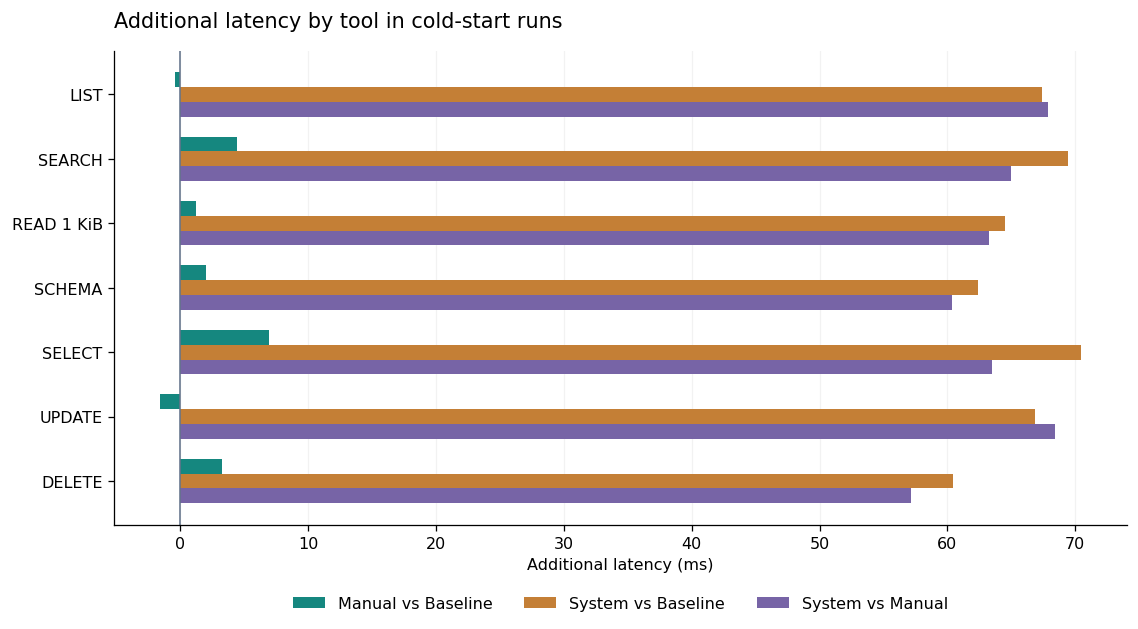

In [18]:
data = overhead.query("mode == 'cold_start' and scenario in @SHORT_OPS")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(10, 5.6))
y, height = np.arange(len(operations)), .23
for i, (_, _, name) in enumerate(PAIRS):
    rows = data[data["comparison"] == name].set_index("scenario").loc[operations]
    ax.barh(y + (i - 1) * height, rows["mean_ms"], height, color=PAIR_COLORS[i], label=name)
ax.set_yticks(y, [NAMES[s] for s in operations])
ax.invert_yaxis()
ax.axvline(0, color="#64748b", linewidth=1)
ax.set_xlabel("Additional latency (ms)")
ax.set_title("Additional latency by tool in cold-start runs", loc="left", fontsize=13, pad=15)
ax.grid(axis="x", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.tight_layout()
fig.savefig(FIGURES / "cold_start_overhead_by_tool.png", dpi=300, bbox_inches="tight")
plt.show()

## 3. Persistent-session experiment

The persistent-session benchmark reuses one initialized MCP session per scenario. Each implementation retains its usual authorization checks.

For short operations, the time spent starting and closing a server can be much larger than the operation itself. Reusing a session makes the differences between the actual tool execution paths easier to examine.

### 3.1. Run 1 results

The first run is examined before combining repeated runs. The table reports the complete statistics from the 30 timed calls for each operation and implementation. All latency values are in milliseconds.

In [19]:
data = run_stats.query("mode == 'persistent_session' and run == 1").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(3))

,,Calls,Mean,Median,p90,p95,p99,SD,IQR,Min,Max
Operation,Implementation,,,,,,,,,,
DELETE,Baseline,30,4.388,4.062,4.695,7.191,8.028,1.079,0.355,3.808,8.031
LIST,Baseline,30,1.270,1.256,1.372,1.375,1.400,0.064,0.086,1.194,1.409
READ 10 MiB,Baseline,30,1160.407,1162.798,1167.815,1172.145,1174.174,7.842,12.054,1146.968,1174.226
READ 1 MiB,Baseline,30,13.854,13.780,14.127,14.342,14.884,0.299,0.205,13.581,15.095
READ 1 KiB,Baseline,30,1.235,1.205,1.313,1.340,1.408,0.059,0.056,1.185,1.429
SCHEMA,Baseline,30,1.274,1.250,1.374,1.393,1.416,0.056,0.059,1.226,1.426
SEARCH,Baseline,30,1.394,1.364,1.463,1.527,1.582,0.066,0.073,1.332,1.601
SELECT,Baseline,30,1.334,1.297,1.480,1.522,1.565,0.092,0.111,1.247,1.576
UPDATE,Baseline,30,1.496,1.461,1.662,1.695,1.721,0.094,0.108,1.402,1.721


#### Latency by operation

Median and p90 latency are compared for the seven filesystem and database operations. The larger file reads are examined separately below.


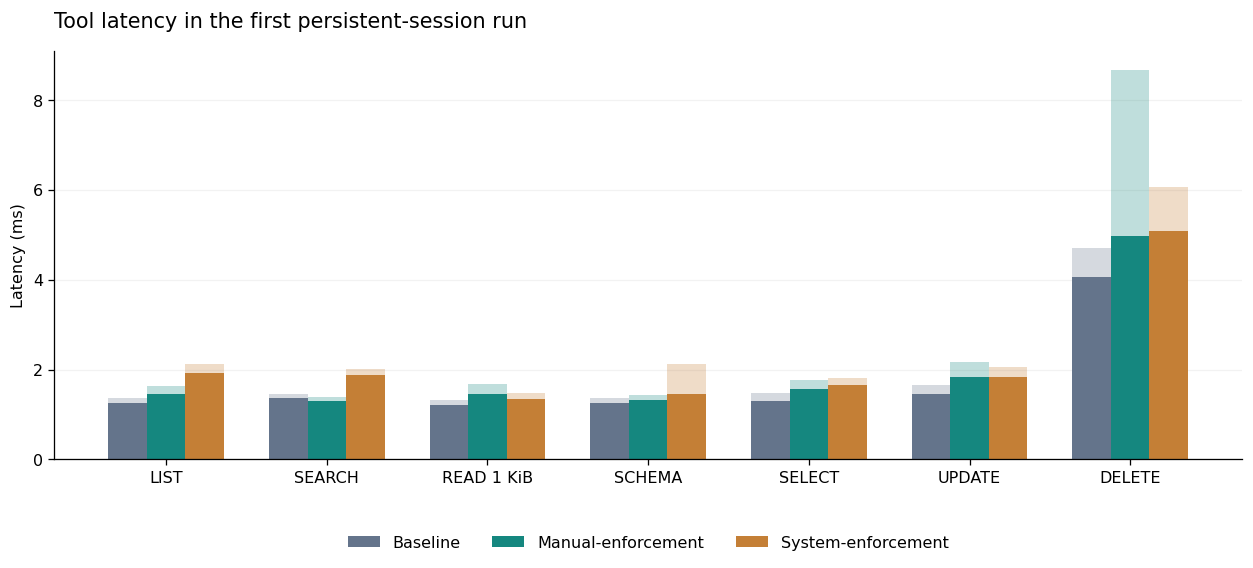

In [20]:
data = run_stats.query("mode == 'persistent_session' and run == 1")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency in the first persistent-session run", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_first_run_tool_latency.png", dpi=300, bbox_inches="tight")
plt.show()

#### Distribution of file-read latency

The distribution for READ 1 KiB retains the individual measurements rather than reducing them to a single summary. A curve further to the left indicates faster calls; a steeper curve indicates less variation.

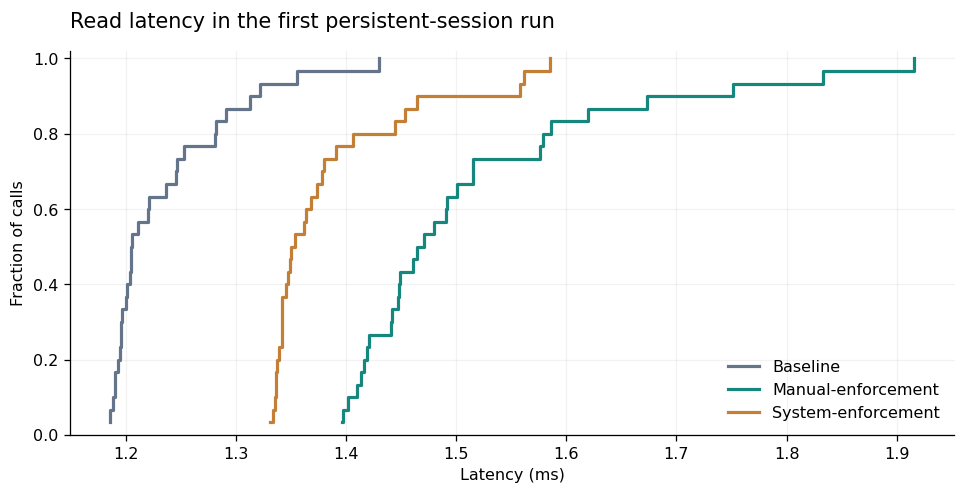

In [21]:
data = samples.query("mode == 'persistent_session' and run == 1 and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    values = np.sort(data.loc[data["version"] == version, "ms"])
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", color=COLORS[version], label=LABELS[version], linewidth=2)
ax.set(xlabel="Latency (ms)", ylabel="Fraction of calls", ylim=(0, 1.02))
ax.set_title("Read latency in the first persistent-session run", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_first_run_read_latency_distribution.png", dpi=300)
plt.show()

### 3.2. Results across six runs

The six repetitions are analyzed independently before the overall comparison. Each value in the following table represents the median of 30 calls from one run.

Since startup is not repeated for every call, the six-run results are particularly important for checking whether small latency differences are consistent.

In [22]:
data = run_stats.query("mode == 'persistent_session'")
by_run = data.pivot(index=["scenario", "version"], columns="run", values="median")
by_run.index = pd.MultiIndex.from_tuples([(NAMES[s], LABELS[v]) for s, v in by_run.index], names=["Operation", "Implementation"])
display(by_run.round(3).rename_axis(columns="Run"))

Run                                    1         2         3         4  \
Operation   Implementation                                               
DELETE      Baseline               4.062     4.112     4.053     4.078   
            Manual-enforcement     4.966     4.758     4.857     4.760   
            System-enforcement     5.076     4.988     5.041     5.043   
LIST        Baseline               1.256     1.230     1.274     1.246   
            Manual-enforcement     1.463     1.390     1.470     1.413   
            System-enforcement     1.929     1.916     1.860     1.876   
READ 10 MiB Baseline            1162.798  1180.222  1164.055  1157.567   
            Manual-enforcement  1182.372  1165.018  1172.881  1157.304   
            System-enforcement  1167.899  1170.740  1167.603  1171.171   
READ 1 MiB  Baseline              13.780    13.827    13.793    13.813   
            Manual-enforcement    14.154    14.834    14.148    14.280   
            System-enforcement    13.955    14.099    14.024    14.358   
READ 1 KiB  Baseline               1.205     1.192     1.232     1.216   
            Manual-enforcement     1.468     1.439     1.539     1.399   
            System-enforcement     1.352     1.362     1.369     1.390   
SCHEMA      Baseline               1.250     1.263     1.241     1.250   
            Manual-enforcement     1.318     1.349     1.314     1.324   
            System-enforcement     1.458     1.351     1.331     1.322   
SEARCH      Baseline               1.364     1.398     1.389     1.397   
            Manual-enforcement     1.312     1.455     1.362     1.337   
            System-enforcement     1.876     1.869     1.888     1.833   
SELECT      Baseline               1.297     1.278     1.304     1.252   
            Manual-enforcement     1.557     1.536     1.534     1.495   
            System-enforcement     1.662     1.719     1.650     1.598   
UPDATE      Baseline               1.461     1.471     1.467     1.469   
            Manual-enforcement     1.843     1.767     1.764     1.802   
            System-enforcement     1.846     1.862     1.837     1.810   

Run                                    5         6  
Operation   Implementation                          
DELETE      Baseline               4.195     4.107  
            Manual-enforcement     4.838     4.838  
            System-enforcement     5.052     5.068  
LIST        Baseline               1.320     1.247  
            Manual-enforcement     1.397     1.438  
            System-enforcement     1.816     1.977  
READ 10 MiB Baseline            1182.123  1176.725  
            Manual-enforcement  1187.420  1177.117  
            System-enforcement  1186.619  1179.278  
READ 1 MiB  Baseline              13.763    13.750  
            Manual-enforcement    14.120    14.069  
            System-enforcement    13.972    14.121  
READ 1 KiB  Baseline               1.199     1.192  
            Manual-enforcement     1.574     1.468  
            System-enforcement     1.353     1.390  
SCHEMA      Baseline               1.280     1.252  
            Manual-enforcement     1.360     1.344  
            System-enforcement     1.353     1.328  
SEARCH      Baseline               1.486     1.404  
            Manual-enforcement     1.311     1.343  
            System-enforcement     1.906     1.860  
SELECT      Baseline               1.268     1.263  
            Manual-enforcement     1.531     1.530  
            System-enforcement     1.586     1.641  
UPDATE      Baseline               1.499     1.468  
            Manual-enforcement     1.820     1.799  
            System-enforcement     1.882     1.805

#### Variation between runs

READ 1 KiB provides a consistent workload for examining changes across the six runs. The lines show the median latency recorded in each run, separately for the three implementations.

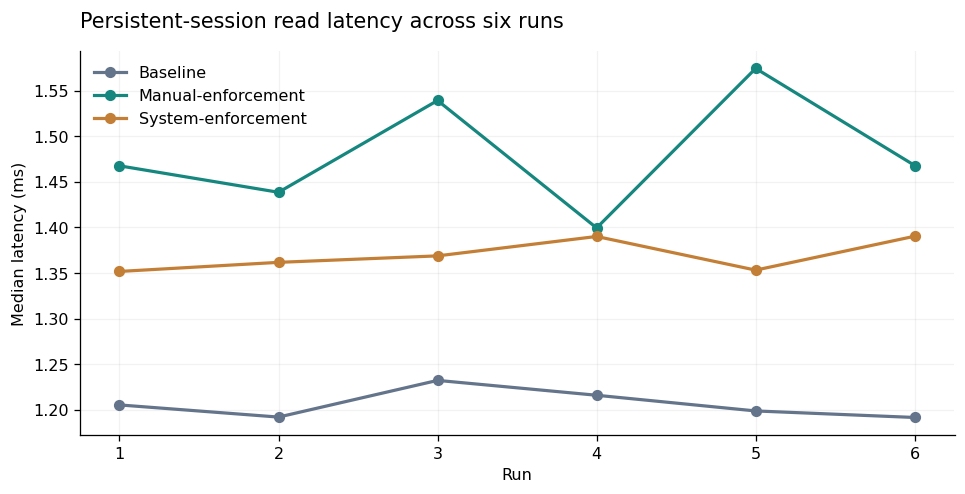

In [23]:
data = run_stats.query("mode == 'persistent_session' and scenario == 'read_small'")
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for version in VERSIONS:
    rows = data[data["version"] == version].sort_values("run")
    ax.plot(rows["run"], rows["median"], marker="o", linewidth=2, color=COLORS[version], label=LABELS[version])
ax.set(xlabel="Run", ylabel="Median latency (ms)", xticks=range(1, 7))
ax.set_title("Persistent-session read latency across six runs", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_read_latency_across_six_runs.png", dpi=300)
plt.show()

#### Overall latency statistics

The following table combines the results of six runs for each scenario. Mean latency is averaged across run means. The median, p90, p95, p99, SD and IQR summarize the corresponding run-level statistics. Between-run SD is calculated from the six run medians. Minimum and maximum refer to individual measured calls.

The detailed table retains the slower calls and variation measures, even though the figures concentrate on median and p90. This allows the typical latency and the spread of timings to be examined together.

In [24]:
data = summary.query("mode == 'persistent_session'").copy()
data["Operation"] = data["scenario"].map(NAMES)
data["Implementation"] = data["version"].map(LABELS)
columns = {"n": "Calls", "mean": "Mean", "median": "Median", "p90": "p90", "p95": "p95", "p99": "p99", "sd": "SD", "iqr": "IQR", "run_sd": "Between-run SD", "minimum": "Min", "maximum": "Max"}
display(data.set_index(["Operation", "Implementation"])[list(columns)].rename(columns=columns).round(3))

Calls      Mean    Median       p90       p95  \
Operation   Implementation                                                      
DELETE      Baseline              180     4.435     4.092     4.887     7.136   
            Manual-enforcement    180     5.314     4.838     6.268     8.201   
            System-enforcement    180     5.434     5.048     6.452     8.763   
LIST        Baseline              180     1.293     1.251     1.370     1.408   
            Manual-enforcement    180     1.471     1.425     1.542     1.590   
            System-enforcement    180     1.925     1.896     2.108     2.147   
READ 10 MiB Baseline              180  1171.274  1170.390  1183.956  1202.026   
            Manual-enforcement    180  1175.607  1174.999  1196.607  1204.519   
            System-enforcement    180  1175.147  1170.956  1185.338  1189.055   
READ 1 MiB  Baseline              180    13.872    13.786    14.105    14.232   
            Manual-enforcement    180    14.343    14.151    14.475    14.676   
            System-enforcement    180    14.147    14.062    14.403    14.629   
READ 1 KiB  Baseline              180     1.225     1.202     1.291     1.333   
            Manual-enforcement    180     1.517     1.468     1.678     1.739   
            System-enforcement    180     1.397     1.365     1.478     1.542   
SCHEMA      Baseline              180     1.285     1.251     1.394     1.439   
            Manual-enforcement    180     1.363     1.334     1.476     1.527   
            System-enforcement    180     1.402     1.341     1.469     1.508   
SEARCH      Baseline              180     1.431     1.398     1.493     1.556   
            Manual-enforcement    180     1.376     1.340     1.477     1.503   
            System-enforcement    180     1.912     1.873     2.010     2.102   
SELECT      Baseline              180     1.310     1.273     1.410     1.454   
            Manual-enforcement    180     1.582     1.533     1.777     1.800   
            System-enforcement    180     1.670     1.646     1.814     1.865   
UPDATE      Baseline              180     1.501     1.469     1.632     1.664   
            Manual-enforcement    180     1.834     1.801     1.976     2.004   
            System-enforcement    180     1.882     1.842     2.030     2.071   

                                     p99      SD     IQR  Between-run SD  \
Operation   Implementation                                                 
DELETE      Baseline               8.339   1.101   0.334           0.052   
            Manual-enforcement     9.057   1.204   0.517           0.076   
            System-enforcement     9.594   1.298   0.480           0.031   
LIST        Baseline               1.464   0.066   0.078           0.032   
            Manual-enforcement     1.637   0.069   0.068           0.034   
            System-enforcement     2.175   0.103   0.105           0.057   
READ 10 MiB Baseline            1209.626  12.441  14.294          10.358   
            Manual-enforcement  1210.228  13.830  16.360          11.136   
            System-enforcement  1214.513  13.782  15.988           7.534   
READ 1 MiB  Baseline              14.538   0.228   0.213           0.029   
            Manual-enforcement    14.830   0.228   0.261           0.286   
            System-enforcement    14.987   0.333   0.345           0.148   
READ 1 KiB  Baseline               1.389   0.055   0.048           0.016   
            Manual-enforcement     1.901   0.122   0.124           0.065   
            System-enforcement     1.615   0.076   0.075           0.017   
SCHEMA      Baseline               1.474   0.071   0.061           0.014   
            Manual-enforcement     1.582   0.078   0.096           0.019   
            System-enforcement     1.575   0.075   0.088           0.051   
SEARCH      Baseline               1.620   0.067   0.084           0.041   
            Manual-enforcement     1.530   0.071   0.080           0.053   
          

#### Latency across operations

The six-run summaries compare median and p90 latency for the same seven operations with a reused MCP session.

The values are much smaller than in Cold-start, so the overhead table is important for interpreting differences that may be small in milliseconds but larger in percentage terms.

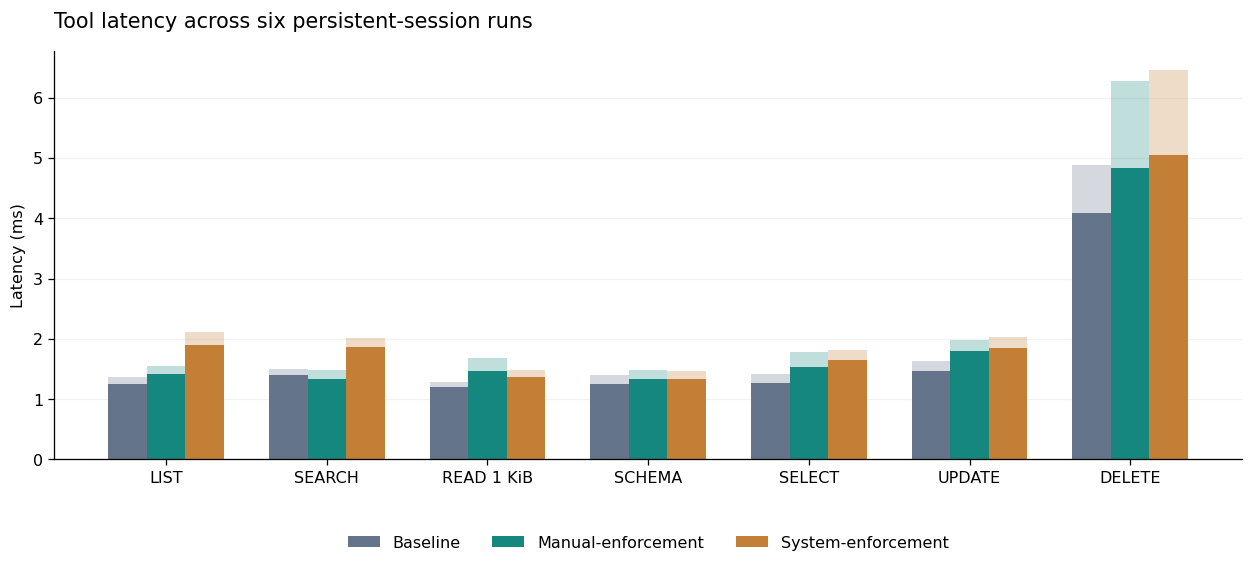

In [25]:
data = summary.query("mode == 'persistent_session' ")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(11, 5.1))
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = data[data["version"] == version].set_index("scenario").loc[operations]
    pos = x + (i - 1) * width
    ax.bar(pos, rows["median"], width, color=COLORS[version], label=LABELS[version])
    ax.bar(pos, rows["p90"] - rows["median"], width, bottom=rows["median"], color=COLORS[version], alpha=.27)
ax.set_xticks(x, [NAMES[s] for s in operations])
ax.set_ylabel("Latency (ms)")
ax.set_title("Tool latency across six persistent-session runs", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.15))
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_tool_latency_six_run_summary.png", dpi=300, bbox_inches="tight")
plt.show()

#### File-read size and latency

The file-read workloads return files of approximately 1 KiB, 1 MiB and 10 MiB. For each file size, all three implementations use the same input size.

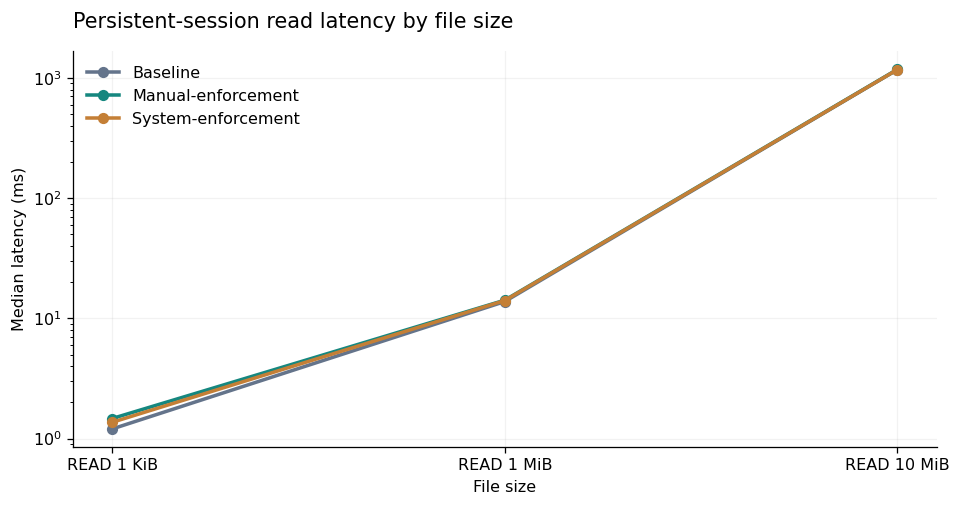

In [26]:
data = summary.query("mode == 'persistent_session'")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
for version in VERSIONS:
    rows = data[data["version"] == version].set_index("scenario").loc[READS]
    ax.plot(range(3), rows["median"], marker="o", linewidth=2.2, color=COLORS[version], label=LABELS[version])
ax.set_xticks(range(3), [NAMES[s] for s in READS])
ax.set_yscale("log")
ax.set(xlabel="File size", ylabel="Median latency (ms)")
ax.set_title("Persistent-session read latency by file size", loc="left", fontsize=13, pad=15)
ax.grid(alpha=.16)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_read_latency_by_file_size.png", dpi=300)
plt.show()

### 3.3. Runtime overhead

The same operation is compared between implementations within each run. The differences are then summarized across six runs. Positive values indicate that the first implementation is slower; negative values indicate that it is faster. The table reports both milliseconds and percentages, with a 95% confidence interval for the mean difference.

The direct System-versus-Manual comparison is especially relevant here because both versions enforce access restrictions through different implementations.

In [27]:
data = overhead.query("mode == 'persistent_session'").copy()
data["Operation"] = data["scenario"].map(NAMES)
columns = {"mean_ms": "Mean Δ (ms)", "median_ms": "Median Δ (ms)", "mean_pct": "Mean Δ (%)", "median_pct": "Median Δ (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}
display(data.set_index(["Operation", "comparison"])[list(columns)].rename(columns=columns).round(3))

Mean Δ (ms)  Median Δ (ms)  Mean Δ (%)  \
Operation   comparison                                                   
DELETE      Manual vs Baseline        0.735          0.707      17.948   
            System vs Baseline        0.944          0.963      23.028   
            System vs Manual          0.208          0.222       4.326   
LIST        Manual vs Baseline        0.166          0.179      13.241   
            System vs Baseline        0.634          0.651      50.356   
            System vs Manual          0.467          0.465      32.757   
READ 10 MiB Manual vs Baseline        3.103          2.844       0.269   
            System vs Baseline        3.303          4.022       0.285   
            System vs Manual          0.200          0.680       0.022   
READ 1 MiB  Manual vs Baseline        0.480          0.365       3.479   
            System vs Baseline        0.301          0.252       2.181   
            System vs Manual         -0.179         -0.136      -1.228   
READ 1 KiB  Manual vs Baseline        0.275          0.269      22.837   
            System vs Baseline        0.163          0.162      13.564   
            System vs Manual         -0.112         -0.097      -7.387   
SCHEMA      Manual vs Baseline        0.079          0.077       6.281   
            System vs Baseline        0.101          0.082       8.066   
            System vs Manual          0.022         -0.000       1.696   
SEARCH      Manual vs Baseline       -0.053         -0.056      -3.681   
            System vs Baseline        0.466          0.464      33.196   
            System vs Manual          0.519          0.522      38.516   
SELECT      Manual vs Baseline        0.254          0.259      19.875   
            System vs Baseline        0.366          0.356      28.634   
            System vs Manual          0.112          0.107       7.310   
UPDATE      Manual vs Baseline        0.327          0.326      22.203   
            System vs Baseline        0.368          0.377      24.975   
            System vs Manual          0.041          0.035       2.297   

                                Median Δ (%)  95% CI low  95% CI high  
Operation   comparison                                                 
DELETE      Manual vs Baseline        17.268       0.628        0.843  
            System vs Baseline        23.541       0.878        1.009  
            System vs Manual           4.594       0.147        0.269  
LIST        Manual vs Baseline        14.327       0.117        0.216  
            System vs Baseline        52.072       0.546        0.721  
            System vs Manual          32.335       0.406        0.529  
READ 10 MiB Manual vs Baseline         0.241      -8.978       15.185  
            System vs Baseline         0.343      -4.477       11.084  
            System vs Manual           0.058      -9.947       10.347  
READ 1 MiB  Manual vs Baseline         2.653       0.204        0.756  
            System vs Baseline         1.827       0.157        0.445  
            System vs Manual          -0.962      -0.488        0.129  
READ 1 KiB  Manual vs Baseline        22.482       0.208        0.343  
            System vs Baseline        13.565       0.140        0.187  
            System vs Manual          -6.620      -0.191       -0.033  
SCHEMA      Manual vs Baseline         6.067       0.069        0.088  
            System vs Baseline         6.531       0.045        0.157  
            System vs Manual          -0.022      -0.039        0.084  
SEARCH      Manual vs Baseline        -4.066      -0.131        0.025  
            System vs Baseline        33.125       0.428        0.503  
            System vs Manual          38.574       0.454        0.584  
SELECT      Manual vs Baseline        20.134       0.239        0.268  
            System vs Baseline        27.892       0.322        0.410  
            System vs Manual           7.054       0.069        0.155  
UPDATE      M

#### Overhead by operation

The three implementation comparisons show the additional latency of authorized tool execution without repeated MCP initialization. Values are mean differences across six runs.


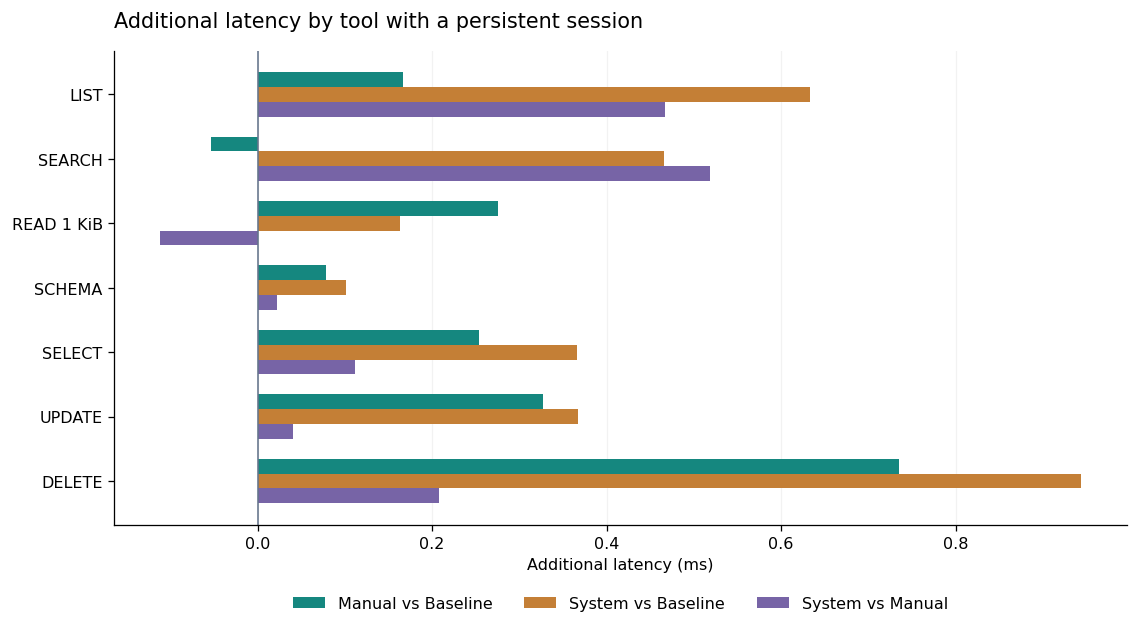

In [28]:
data = overhead.query("mode == 'persistent_session' and scenario in @SHORT_OPS")
operations = SHORT_OPS
fig, ax = plt.subplots(figsize=(10, 5.6))
y, height = np.arange(len(operations)), .23
for i, (_, _, name) in enumerate(PAIRS):
    rows = data[data["comparison"] == name].set_index("scenario").loc[operations]
    ax.barh(y + (i - 1) * height, rows["mean_ms"], height, color=PAIR_COLORS[i], label=name)
ax.set_yticks(y, [NAMES[s] for s in operations])
ax.invert_yaxis()
ax.axvline(0, color="#64748b", linewidth=1)
ax.set_xlabel("Additional latency (ms)")
ax.set_title("Additional latency by tool with a persistent session", loc="left", fontsize=13, pad=15)
ax.grid(axis="x", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12))
fig.tight_layout()
fig.savefig(FIGURES / "persistent_session_overhead_by_tool.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Cold-start and Persistent-session comparison

The two experiments measure different execution paths. Cold-start includes repeated MCP server initialization, while Persistent-session measures tool calls after a session has been established. Their difference indicates the effect of the execution mode, not the isolated cost of an authorization decision.

The comparison therefore concerns two ways of executing the same benchmark scenarios, not two different authorization policies. We keep the performance of each tool visible instead of averaging all operations together.

### 4.1. Latency change with session reuse

The table compares median latency across the two modes for each scenario and implementation. It also reports the absolute reduction, percentage reduction and Cold-start/Persistent-session latency ratio.

In [29]:
modes = summary.pivot(index=["scenario", "version"], columns="mode", values="median").reset_index()
modes["reduction_ms"] = modes["cold_start"] - modes["persistent_session"]
modes["reduction_pct"] = 100 * modes["reduction_ms"] / modes["cold_start"]
modes["ratio"] = modes["cold_start"] / modes["persistent_session"]
modes["Operation"] = modes["scenario"].map(NAMES)
modes["Implementation"] = modes["version"].map(LABELS)
display(modes.set_index(["Operation", "Implementation"])[["cold_start", "persistent_session", "reduction_ms", "reduction_pct", "ratio"]].rename(columns={"cold_start": "Cold (ms)", "persistent_session": "Persistent (ms)", "reduction_ms": "Reduction (ms)", "reduction_pct": "Reduction (%)", "ratio": "Latency ratio"}).round(2))

mode                            Cold (ms)  Persistent (ms)  Reduction (ms)  \
Operation   Implementation                                                   
DELETE      Baseline               770.06             4.09          765.97   
            Manual-enforcement     777.65             4.84          772.82   
            System-enforcement     833.94             5.05          828.89   
LIST        Baseline               745.50             1.25          744.25   
            Manual-enforcement     748.33             1.43          746.90   
            System-enforcement     808.91             1.90          807.02   
READ 10 MiB Baseline              1717.32          1170.39          546.93   
            Manual-enforcement    1744.38          1175.00          569.38   
            System-enforcement    1788.54          1170.96          617.58   
READ 1 MiB  Baseline               756.06            13.79          742.27   
            Manual-enforcement     769.62            14.15          755.47   
            System-enforcement     820.94            14.06          806.88   
READ 1 KiB  Baseline               742.27             1.20          741.07   
            Manual-enforcement     751.76             1.47          750.29   
            System-enforcement     807.00             1.37          805.63   
SCHEMA      Baseline               743.74             1.25          742.49   
            Manual-enforcement     748.55             1.33          747.22   
            System-enforcement     808.81             1.34          807.47   
SEARCH      Baseline               742.77             1.40          741.37   
            Manual-enforcement     750.23             1.34          748.89   
            System-enforcement     808.39             1.87          806.52   
SELECT      Baseline               743.83             1.27          742.55   
            Manual-enforcement     756.14             1.53          754.61   
            System-enforcement     817.28             1.65          815.64   
UPDATE      Baseline               746.80             1.47          745.33   
            Manual-enforcement     753.96             1.80          752.16   
            System-enforcement     821.53             1.84          819.69   

mode                            Reduction (%)  Latency ratio  
Operation   Implementation                                    
DELETE      Baseline                    99.47         188.17  
            Manual-enforcement          99.38         160.74  
            System-enforcement          99.39         165.20  
LIST        Baseline                    99.83         595.81  
            Manual-enforcement          99.81         525.06  
            System-enforcement          99.77         426.63  
READ 10 MiB Baseline                    31.85           1.47  
            Manual-enforcement          32.64           1.48  
            System-enforcement          34.53           1.53  
READ 1 MiB  Baseline                    98.18          54.84  
            Manual-enforcement          98.16          54.39  
            System-enforcement          98.29          58.38  
READ 1 KiB  Baseline                    99.84         617.52  
            Manual-enforcement          99.80         512.17  
            System-enforcement          99.83         591.09  
SCHEMA      Baseline                    99.83         594.52  
            Manual-enforcement          99.82         561.18  
            System-enforcement          99.83         603.30  
SEARCH      Baseline                    99.81         531.45  
            Manual-enforcement          99.82         559.97  
            System-enforcement          99.77         431.64  
SELECT      Baseline                    99.83         584.19  
            Manual-enforcement          99.80         493.36  
            System-enforcement          99.80         496.65  
UPDATE      Baseline                    99.80         508.53  
            Manual-enforcement      

#### Reduction in execution time

The absolute reduction shows how many milliseconds are saved by reusing the MCP session. Short and long-running operations remain comparable because the chart measures the difference in milliseconds rather than percentages that approach 100% for nearly every short operation.

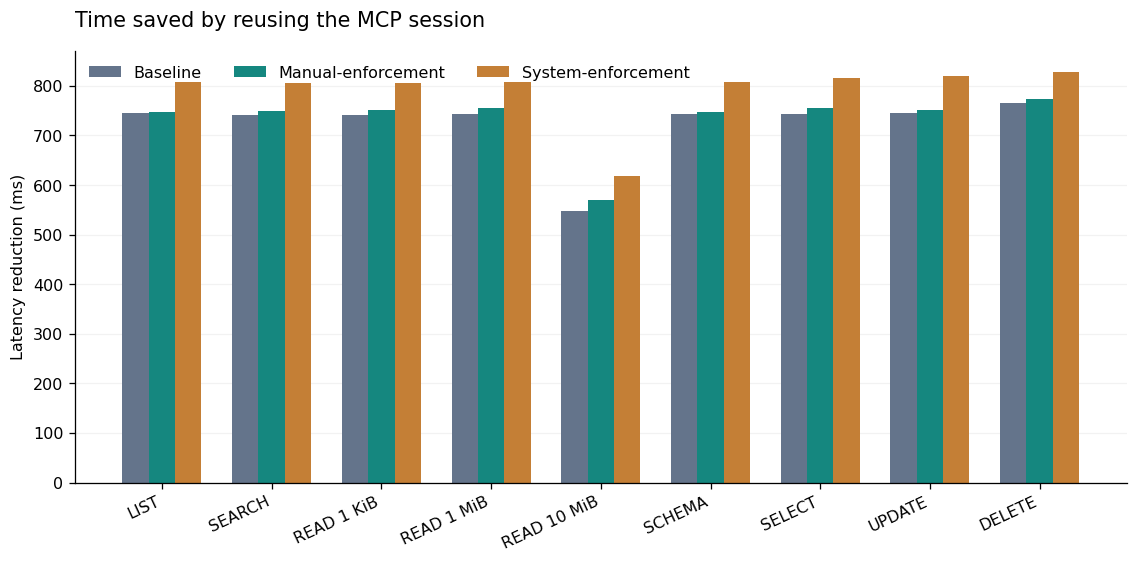

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
operations = SCENARIOS
x, width = np.arange(len(operations)), .24
for i, version in enumerate(VERSIONS):
    rows = modes[modes["version"] == version].set_index("scenario").loc[operations]
    ax.bar(x + (i - 1) * width, rows["reduction_ms"], width, color=COLORS[version], label=LABELS[version])
ax.set_xticks(x, [NAMES[s] for s in operations], rotation=25, ha="right")
ax.set_ylabel("Latency reduction (ms)")
ax.set_title("Time saved by reusing the MCP session", loc="left", fontsize=13, pad=15)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "latency_reduction_with_persistent_session.png", dpi=300)
plt.show()

### 4.2. Overhead across file sizes

The file-read results compare System-enforcement with Manual-enforcement for the three payload sizes. Absolute and percentage differences are reported together, because a small difference in milliseconds can represent a large percentage for a fast operation.

Absolute overhead shows the time difference, while percentage overhead indicates how large that difference is relative to manual enforcement. Both are needed when the file sizes span several orders of magnitude.

In [31]:
data = overhead.query("scenario in @READS and comparison == 'System vs Manual'").copy()
data["Read workload"] = data["scenario"].map(NAMES)
display(data.set_index(["mode", "Read workload"])[["mean_ms", "mean_pct", "ci_low", "ci_high"]].rename(columns={"mean_ms": "Difference (ms)", "mean_pct": "Difference (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}).round(2))

Difference (ms)  Difference (%)  95% CI low  \
mode               Read workload                                                
cold_start         READ 10 MiB              58.56            3.39       40.87   
                   READ 1 MiB               56.60            7.37       49.28   
                   READ 1 KiB               63.22            8.45       51.39   
persistent_session READ 10 MiB               0.20            0.02       -9.95   
                   READ 1 MiB               -0.18           -1.23       -0.49   
                   READ 1 KiB               -0.11           -7.39       -0.19   

                                  95% CI high  
mode               Read workload               
cold_start         READ 10 MiB          76.25  
                   READ 1 MiB           63.92  
                   READ 1 KiB           75.05  
persistent_session READ 10 MiB          10.35  
                   READ 1 MiB            0.13  
                   READ 1 KiB           -0.03

#### Relative overhead by file size

Percentage overhead is compared across file sizes for both execution modes. A negative value means the System was faster than Manual-enforcement for that workload.

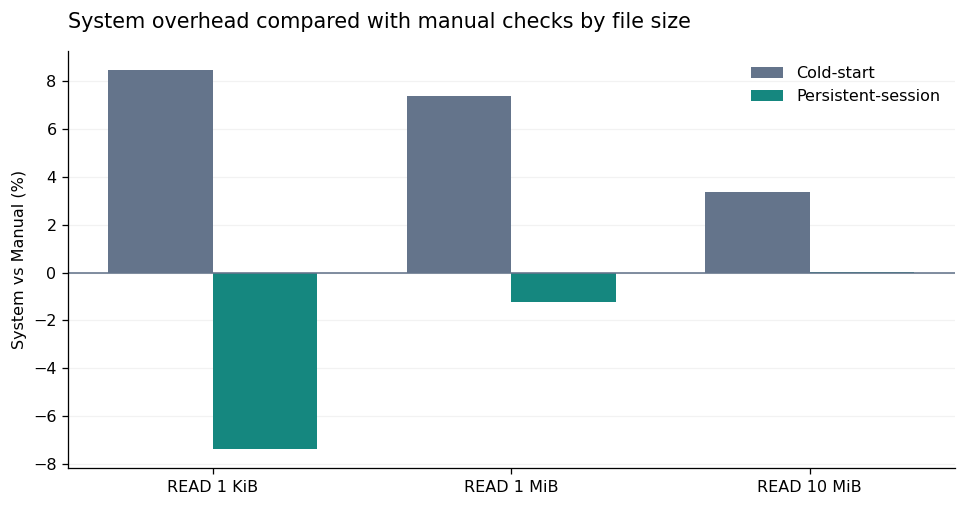

In [32]:
data = overhead.query("scenario in @READS and comparison == 'System vs Manual'")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
x, width = np.arange(3), .35
for i, (mode, label, color) in enumerate([("cold_start", "Cold-start", "#64748b"), ("persistent_session", "Persistent-session", "#15877f")]):
    rows = data[data["mode"] == mode].set_index("scenario").loc[READS]
    ax.bar(x + (i - .5) * width, rows["mean_pct"], width, color=color, label=label)
ax.set_xticks(x, [NAMES[s] for s in READS])
ax.set_ylabel("System vs Manual (%)")
ax.set_title("System overhead compared with manual checks by file size", loc="left", fontsize=13, pad=15)
ax.axhline(0, color="#64748b", linewidth=1)
ax.grid(axis="y", alpha=.16)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "system_vs_manual_overhead_by_file_size.png", dpi=300)
plt.show()

### 4.3. Returned data and comparability

LIST, SEARCH and SCHEMA may return different amounts or scopes of information between implementations. Their observed differences can reflect both enforcement and the amount of work performed. The input and response sizes are retained to identify these cases; file reads provide a more closely matched workload.

Where an implementation returns a smaller or differently scoped result, the time difference should not be interpreted as the isolated cost of its policy checks.

In [33]:
sizes = summary[["mode", "scenario", "version", "input_bytes", "response_bytes"]].copy()
sizes["Operation"] = sizes["scenario"].map(NAMES)
sizes["Implementation"] = sizes["version"].map(LABELS)
display(sizes.set_index(["mode", "Operation", "Implementation"])[["input_bytes", "response_bytes"]].rename(columns={"input_bytes": "Input bytes", "response_bytes": "Response bytes"}).round(0))

Input bytes  Response bytes
mode               Operation   Implementation                                 
cold_start         DELETE      Baseline                    NaN            25.0
                               Manual-enforcement          NaN            17.0
                               System-enforcement          NaN            25.0
                   LIST        Baseline                    NaN           863.0
                               Manual-enforcement          NaN           188.0
                               System-enforcement          NaN           863.0
                   READ 10 MiB Baseline             10485760.0      10485760.0
                               Manual-enforcement   10485760.0      10485760.0
                               System-enforcement   10485760.0      10485760.0
                   READ 1 MiB  Baseline              1048576.0       1048576.0
                               Manual-enforcement    1048576.0       1048576.0
                               System-enforcement    1048576.0       1048576.0
                   READ 1 KiB  Baseline                 1024.0          1024.0
                               Manual-enforcement       1024.0          1024.0
                               System-enforcement       1024.0          1024.0
                   SCHEMA      Baseline                    NaN          3081.0
                               Manual-enforcement          NaN            62.0
                               System-enforcement          NaN            54.0
                   SEARCH      Baseline                    NaN           169.0
                               Manual-enforcement          NaN             9.0
                               System-enforcement          NaN            84.0
                   SELECT      Baseline                    NaN            67.0
                               Manual-enforcement          NaN            67.0
                               System-enforcement          NaN            67.0
                   UPDATE      Baseline                    NaN            30.0
                               Manual-enforcement          NaN            30.0
                               System-enforcement          NaN            30.0
persistent_session DELETE      Baseline                    NaN            25.0
                               Manual-enforcement          NaN            17.0
                               System-enforcement          NaN            25.0
                   LIST        Baseline                    NaN           863.0
                               Manual-enforcement          NaN           188.0
                               System-enforcement          NaN           863.0
                   READ 10 MiB Baseline             10485760.0      10485760.0
                               Manual-enforcement   10485760.0      10485760.0
                               System-enforcement   10485760.0      10485760.0
                   READ 1 MiB  Baseline              1048576.0       1048576.0
                               Manual-enforcement    1048576.0       1048576.0
                               System-enforcement    1048576.0       1048576.0
                   READ 1 KiB  Baseline                 1024.0          1024.0
                               Manual-enforcement       1024.0          1024.0
                               System-enforcement       1024.0          1024.0
                   SCHEMA      Baseline                    NaN          3081.0
                               Manual-enforcement          NaN            62.0
                               System-enforcement          NaN            54.0
                   SEARCH      Baseline                    NaN           169.0
                               Manual-enforcement          NaN             9.0
                               System-enforcement          NaN            84.0
                   SELECT      Baseline                    NaN            67.0
                      

## 5. Results summary

The primary architectural comparison is **System-enforcement versus Manual-enforcement** because both implementations enforce access restrictions. Baseline provides a reference for the additional runtime cost of introducing access control. Results are reported separately by operation and execution mode rather than averaged across unrelated workloads.

The table below brings together the main differences between the two secured implementations. The previous sections provide their full timing statistics, variation across runs and corresponding baseline comparisons.

The important question is whether any additional cost is concentrated in particular operations and whether those differences remain when the MCP session is reused.

In [34]:
data = overhead.query("comparison == 'System vs Manual'").copy()
data["Operation"] = data["scenario"].map(NAMES)
display(data.set_index(["mode", "Operation"])[["mean_ms", "median_ms", "mean_pct", "ci_low", "ci_high"]].rename(columns={"mean_ms": "Mean Δ (ms)", "median_ms": "Median Δ (ms)", "mean_pct": "Mean Δ (%)", "ci_low": "95% CI low", "ci_high": "95% CI high"}).round(3))

Mean Δ (ms)  Median Δ (ms)  Mean Δ (%)  \
mode               Operation                                             
cold_start         DELETE            57.116         58.907       7.353   
                   LIST              67.836         65.543       9.051   
                   READ 10 MiB       58.557         59.692       3.388   
                   READ 1 MiB        56.600         57.069       7.373   
                   READ 1 KiB        63.221         64.056       8.452   
                   SCHEMA            60.363         64.618       8.045   
                   SEARCH            64.980         67.062       8.683   
                   SELECT            63.522         66.329       8.424   
                   UPDATE            68.422         67.253       9.086   
persistent_session DELETE             0.208          0.222       4.326   
                   LIST               0.467          0.465      32.757   
                   READ 10 MiB        0.200          0.680       0.022   
                   READ 1 MiB        -0.179         -0.136      -1.228   
                   READ 1 KiB        -0.112         -0.097      -7.387   
                   SCHEMA             0.022         -0.000       1.696   
                   SEARCH             0.519          0.522      38.516   
                   SELECT             0.112          0.107       7.310   
                   UPDATE             0.041          0.035       2.297   

                                95% CI low  95% CI high  
mode               Operation                             
cold_start         DELETE           45.454       68.779  
                   LIST             59.320       76.351  
                   READ 10 MiB      40.867       76.247  
                   READ 1 MiB       49.279       63.920  
                   READ 1 KiB       51.387       75.055  
                   SCHEMA           49.021       71.706  
                   SEARCH           52.628       77.333  
                   SELECT           48.497       78.546  
                   UPDATE           51.100       85.743  
persistent_session DELETE            0.147        0.269  
                   LIST              0.406        0.529  
                   READ 10 MiB      -9.947       10.347  
                   READ 1 MiB       -0.488        0.129  
                   READ 1 KiB       -0.191       -0.033  
                   SCHEMA           -0.039        0.084  
                   SEARCH            0.454        0.584  
                   SELECT            0.069        0.155  
                   UPDATE           -0.002        0.083

### 5.1. Saved results

The full measurements, run-level statistics, six-run summaries, overhead comparisons, returned-data sizes and figures are exported for reporting and further analysis.

In [35]:
tables = {"individual_timings.csv": samples, "report_metadata.csv": report_info, "per_run_statistics.csv": run_stats, "six_run_summary.csv": summary, "per_run_differences.csv": differences, "overhead_comparison.csv": overhead, "cold_vs_persistent.csv": modes}
for filename, data in tables.items():
    data.to_csv(OUTPUT / filename, index=False)
print(f"Saved {len(tables)} result tables to {OUTPUT}")

Saved 7 result tables to /Users/enasbatarfi/agentic_security_evaluation/results/runtime_overhead/analysis
